In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv('car_sales_data.csv', sep=',', encoding='mac_cyrillic')

columns = df.columns
print(f"Всего пропусков: {df.isnull().sum().sum()}")
print(f"Всего (строк, столбцов): {df.shape}")
print()
print(f"Столбцы: {columns}")

numerical_variables = ['Объем двигателя', 'Год выпуска', 'Пробег (в милях)', 'Цена'] # количественные пременные
qualitative_variables = ['Марка', 'Модель', 'Тип топлива']  # качественные переменные


Всего пропусков: 0
Всего (строк, столбцов): (50000, 7)

Столбцы: Index(['Марка', 'Модель', 'Объем двигателя', 'Тип топлива', 'Год выпуска',
       'Пробег (в милях)', 'Цена'],
      dtype='str')


## Анализ выбросов
Метод межквартального размаха показал достаточно большое количество выбросов. При проверке такими оказались **объем двигателя**, **пробег** и **цена**. Данные признаки являются слишком сильно разбросанными но это абсолютно нормально (цена разных классов автомобилей может различаться в сотни раз; объем двигателя больше сосредоточен к 1.6 литрам из-за большей популярности эконом-класса; пробег аналогично). В дальнейшем нужно будет учесть "аномальный разброс" и проверить логарифмирование может ли исправить ситуацию

3951 строк с выбросами в столбце 'Объем двигателя'
23857 строк с выбросами в столбце 'Год выпуска'
25000 строк с выбросами в столбце 'Пробег (в милях)'
24998 строк с выбросами в столбце 'Цена'


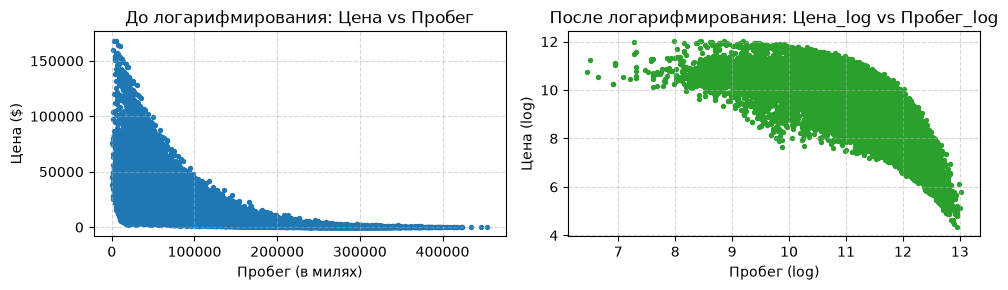

In [8]:
for column in numerical_variables:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q_3 - q_1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    np_trash = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    print(len(np_trash), f"строк с выбросами в столбце '{column}'")

df['Цена_log'] = np.log1p(df['Цена'])
df['Пробег_log'] = np.log1p(df['Пробег (в милях)'])

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].scatter(df['Пробег (в милях)'], df['Цена'], s=8, c='tab:blue')
axes[0].set_title('До логарифмирования: Цена vs Пробег', fontsize=12)
axes[0].set_xlabel('Пробег (в милях)', fontsize=10)
axes[0].set_ylabel('Цена ($)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].scatter(df['Пробег_log'], df['Цена_log'], s=8, c='tab:green')
axes[1].set_title('После логарифмирования: Цена_log vs Пробег_log', fontsize=12)
axes[1].set_xlabel('Пробег (log)', fontsize=10)
axes[1].set_ylabel('Цена (log)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Анализ логарифмирования и возможность использовать коэффициент корреляции Пирсона

Без шансов, не помогло :(

In [9]:
print(df.columns)

Index(['Марка', 'Модель', 'Объем двигателя', 'Тип топлива', 'Год выпуска',
       'Пробег (в милях)', 'Цена', 'Цена_log', 'Пробег_log'],
      dtype='str')


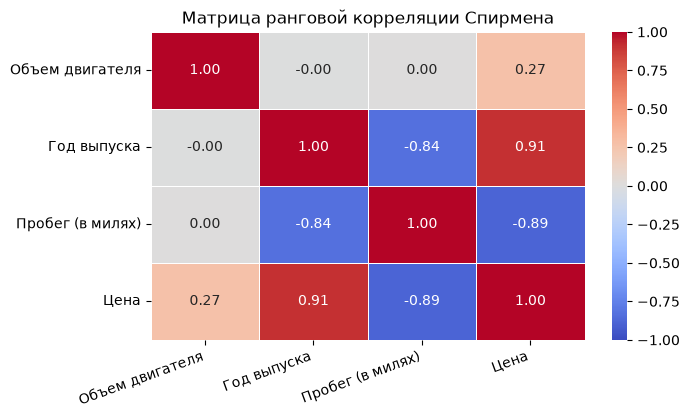

In [10]:
corr_columns = ['Объем двигателя', 'Год выпуска', 'Пробег (в милях)', 'Цена']

spearman_matrix = df[corr_columns].corr(method='spearman')

plt.figure(figsize=(7, 4))
sns.heatmap(
    spearman_matrix, 
    annot=True,          # выводим числа внутри ячеек
    fmt='.2f',           # округляем до 2 знаков
    cmap='coolwarm',     # красивая цветовая гамма (синий - отрицательная, красный - положительная)
    vmin=-1, vmax=1,     # границы шкалы
    linewidths=0.5
)

plt.title('Матрица ранговой корреляции Спирмена', fontsize=12)
plt.xticks(rotation=20, ha='right')
plt.show()